## *Linear Regression*


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv(r"C:\GEN_AI\Dummy\dummy3.csv")

print(df.head())
print(df.info())

  Car_Name          Brand  Year       Price Fuel_Type Transmission  Mileage  \
0    Swift  Maruti Suzuki  2022   ₹7,50,000    Petrol       Manual     22.0   
1    Creta        Hyundai  2023  ₹14,00,000    Diesel    Automatic     18.0   
2    Nexon           Tata  2024  ₹12,50,000    Petrol       Manual     17.5   
3   Innova         Toyota  2022  ₹22,00,000    Diesel    Automatic     15.0   
4     City          Honda  2021  ₹12,00,000    Petrol    Automatic     17.8   

   Seats  
0      5  
1      5  
2      5  
3      7  
4      5  
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car_Name      10 non-null     str    
 1   Brand         10 non-null     str    
 2   Year          10 non-null     int64  
 3   Price         10 non-null     str    
 4   Fuel_Type     10 non-null     str    
 5   Transmission  10 non-null     str    
 6   Mileage       10 non

In [3]:
df['Price'] = (
    df['Price']
    .str.replace(r'[^\d]', '', regex=True)
    .astype(int)
)

print(df['Price'])

0     750000
1    1400000
2    1250000
3    2200000
4    1200000
5    1800000
6     800000
7    4200000
8     850000
9    1500000
Name: Price, dtype: int64


In [4]:
X = df[
    ['Brand', 'Year', 'Fuel_Type',
     'Transmission', 'Mileage', 'Seats']
]

y = df['Price']

In [14]:
categorical = [
    'Brand',
    'Fuel_Type',
    'Transmission'
]

numerical = [
    'Year',
    'Mileage',
    'Seats'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
        ('num', 'passthrough', numerical)
    ]
)



In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [7]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Brand','Year','Fuel_Type','Transmission','Mileage','Seats']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis conca

In [8]:
y_pred = model.predict(X_test)

print("Actual prices:", y_test.values)
print("Predicted prices:", y_pred)

Actual prices: [ 850000 1400000]
Predicted prices: [ 618483.70547277 1387242.70332718]


In [9]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 122136.79560002685
MSE: 26881271625.00935
RMSE: 163955.09026867495
R2 Score: 0.6445451685949177


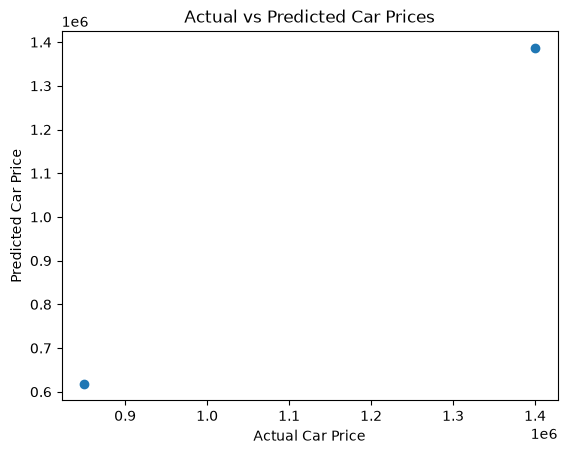

In [10]:
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")

plt.title("Actual vs Predicted Car Prices")

plt.show()

In [11]:
new_car = pd.DataFrame({
    'Brand': ['Hyundai'],
    'Year': [2024],
    'Fuel_Type': ['Petrol'],
    'Transmission': ['Manual'],
    'Mileage': [20.0],
    'Seats': [5]
})

predicted_price = model.predict(new_car)

print("Predicted Car Price: ₹", round(predicted_price[0], 2))

Predicted Car Price: ₹ 1201230.41
